# CSET485 – AI and Society · Assignment 1
## Stress-testing a credit-approval model (German Credit Data)

* **Roll number (last 3 digits):** 453 → last digit **3** → **German Credit Data** (UCI Statlog)
* **Random seed:** `random_state = 453` for the 70/30 train–test split (and every other random step)
* **Target:** `approve = 1` if the applicant was a *good* credit risk (UCI class 1), `0` if *bad* (UCI class 2)

Run every cell top to bottom (`Kernel → Restart & Run All`). Every number quoted in the PDF report is printed below
and is also written to `results.json`; every figure is saved in `figures/`.

**Note on wording.** The assignment template says “high risk” for the positive class. For German Credit the positive class
is *approve* (Ŷ = 1), so in this notebook “flagged” / “high” means *predicted approve*. The mechanics (median threshold for
Model A, 0.5 threshold for Model B) are exactly as specified.

In [1]:
import os, json, hashlib, io, warnings
import numpy as np, pandas as pd
import statsmodels.api as sm
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from scipy.stats import chi2

warnings.filterwarnings("ignore")
SEED = 453
np.random.seed(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 50)
os.makedirs("figures", exist_ok=True)
R = {}          # every reported number is stored here and dumped to results.json at the end
def r3(x): return None if x is None or (isinstance(x, float) and not np.isfinite(x)) else round(float(x), 6)

## 0. Load the data
The official source is `https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data`
(space-separated, 1000 rows, 20 attributes + class). If UCI is unreachable the notebook falls back to a byte-for-byte
comma-separated mirror of the same file on GitHub. The row count, class balance and a checksum of the parsed values are
printed so the two sources can be confirmed identical.

In [2]:
COLS = ["checking","duration","credit_history","purpose","credit_amount","savings","employment",
        "installment_rate","personal_status_sex","other_debtors","residence_since","property","age",
        "other_installments","housing","existing_credits","job","people_liable","telephone",
        "foreign_worker","target"]
UCI = "https://archive.ics.uci.edu/ml/machine-learning-databases/statlog/german/german.data"
MIRROR = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/german.csv"
LOCAL = "german.data.csv"

def load():
    if os.path.exists(LOCAL):
        return pd.read_csv(LOCAL, header=None, names=COLS), "local cache"
    try:
        d = pd.read_csv(UCI, sep=r"\s+", header=None, names=COLS); src = "UCI"
    except Exception as e:
        print("UCI unavailable (", type(e).__name__, ") -> using GitHub mirror")
        d = pd.read_csv(MIRROR, header=None, names=COLS); src = "GitHub mirror"
    d.to_csv(LOCAL, header=False, index=False)
    return d, src

raw, source = load()
checksum = hashlib.sha256(raw.to_csv(index=False).encode()).hexdigest()[:16]
print("source:", source, "| shape:", raw.shape, "| checksum:", checksum)
print(raw.target.value_counts().rename({1: "good (1)", 2: "bad (2)"}))
raw.head()

source: local cache | shape: (1000, 21) | checksum: a675c94854b2e9d9
target
good (1)    700
bad (2)     300
Name: count, dtype: int64


,checking,duration,credit_history,purpose,credit_amount,savings,employment,installment_rate,personal_status_sex,other_debtors,residence_since,property,age,other_installments,housing,existing_credits,job,people_liable,telephone,foreign_worker,target
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


## 1. Data preprocessing (documented)

| Step | Decision | Reason |
|---|---|---|
| **Missing values** | Checked every column: **0 missing values**. Categorical “unknown” levels (e.g. savings *unknown/none*, property *unknown/none*) are real UCI categories, not missing data, so they are kept as their own category. | Nothing to impute; dropping or imputing “unknown” would destroy information (it turns out to be predictive). |
| **Categorical encoding** | 13 categorical attributes one-hot encoded with the **first UCI level as reference** (drop-first) → 41 dummies. Codes (A11…A202) are renamed to readable labels. | Avoids perfect collinearity with the intercept; coefficients read as “vs reference level”. |
| **Outliers** | IQR rule (1.5×IQR) flags 72 credit amounts, 70 durations, 23 ages. All are plausible (max loan 18,424 DM, max duration 72 months, max age 75), so **no rows are removed**. `credit_amount` (skew 1.95) is **log-transformed**; `people_liable` is effectively binary (1/2) so its “outliers” are just the value 2. | Only 1000 rows: deleting genuine large loans would bias the sample. The log removes the long right tail that otherwise gives a few loans huge leverage in OLS/logit. |
| **Feature scaling** | 7 numeric features standardised (z-scores). For the train/test models (Parts 1, 2.3, 2.4) the scaler is **fit on the training set only**; for the inference models fit on all 1000 rows (Parts 2.1, 2.2) it is fit on all rows. | Makes numeric coefficients comparable (“per 1 SD”) and prevents test-set leakage. |
| **Derived variables** | `approve` (target), `female` (personal_status_sex ∈ {A92, A95}), `young` (age ≤ 25). | Needed for the subgroup and fairness analyses. |

In [3]:
df = raw.copy()
R["n_rows"] = len(df); R["source"] = source
R["missing_total"] = int(df.isna().sum().sum())
print("Missing values per column:\n", df.isna().sum().to_string())

df["approve"] = (df.target == 1).astype(int)
df["female"] = df.personal_status_sex.isin(["A92", "A95"]).astype(int)
df["young"] = (df.age <= 25).astype(int)
R["approve_rate"] = r3(df.approve.mean())

NUM_RAW = ["duration","credit_amount","installment_rate","residence_since","age","existing_credits","people_liable"]
out = []
for c in NUM_RAW:
    q1, q3 = df[c].quantile([.25, .75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5*iqr) | (df[c] > q3 + 1.5*iqr)).sum())
    out.append([c, df[c].min(), df[c].median(), df[c].max(), round(df[c].skew(), 2), n_out])
outliers = pd.DataFrame(out, columns=["feature","min","median","max","skew","IQR_outliers"])
R["outliers"] = outliers.to_dict(orient="records")
print(outliers.to_string(index=False))

df["log_amount"] = np.log(df.credit_amount)
print("skew of log(credit_amount):", round(df.log_amount.skew(), 2))
R["log_amount_skew"] = r3(df.log_amount.skew())

Missing values per column:
 checking               0
duration               0
credit_history         0
purpose                0
credit_amount          0
savings                0
employment             0
installment_rate       0
personal_status_sex    0
other_debtors          0
residence_since        0
property               0
age                    0
other_installments     0
housing                0
existing_credits       0
job                    0
people_liable          0
telephone              0
foreign_worker         0
target                 0
         feature  min  median   max  skew  IQR_outliers
        duration    4    18.0    72  1.09            70
   credit_amount  250  2319.5 18424  1.95            72
installment_rate    1     3.0     4 -0.53             0
 residence_since    1     3.0     4 -0.27             0
             age   19    33.0    75  1.02            23
existing_credits    1     1.0     4  1.27             6
   people_liable    1     1.0     2  1.91           155

In [4]:
LABELS = {
 "checking": {"A11":"<0DM","A12":"0-200DM","A13":">=200DM","A14":"no_account"},
 "credit_history": {"A30":"none_or_all_paid","A31":"all_paid_this_bank","A32":"existing_paid","A33":"past_delay","A34":"critical_account"},
 "purpose": {"A40":"car_new","A41":"car_used","A42":"furniture","A43":"radio_tv","A44":"appliances","A45":"repairs",
             "A46":"education","A47":"vacation","A48":"retraining","A49":"business","A410":"other"},
 "savings": {"A61":"<100DM","A62":"100-500DM","A63":"500-1000DM","A64":">=1000DM","A65":"unknown_none"},
 "employment": {"A71":"unemployed","A72":"<1yr","A73":"1-4yr","A74":"4-7yr","A75":">=7yr"},
 "personal_status_sex": {"A91":"male_div_sep","A92":"female_div_sep_mar","A93":"male_single","A94":"male_mar_wid","A95":"female_single"},
 "other_debtors": {"A101":"none","A102":"co_applicant","A103":"guarantor"},
 "property": {"A121":"real_estate","A122":"savings_insurance","A123":"car_other","A124":"unknown_none"},
 "other_installments": {"A141":"bank","A142":"stores","A143":"none"},
 "housing": {"A151":"rent","A152":"own","A153":"free"},
 "job": {"A171":"unskilled_nonres","A172":"unskilled_res","A173":"skilled","A174":"management"},
 "telephone": {"A191":"none","A192":"yes"},
 "foreign_worker": {"A201":"yes","A202":"no"},
}
CAT = list(LABELS)
NUM = ["duration","log_amount","installment_rate","residence_since","age","existing_credits","people_liable"]

lab = df[CAT].copy()
for c in CAT:   # ordered categoricals so that drop_first drops the first UCI level (the reference)
    lab[c] = pd.Categorical(df[c].map(LABELS[c]), categories=[v for k, v in LABELS[c].items() if k in set(df[c])])
DUMMIES = pd.get_dummies(lab, prefix_sep="=", drop_first=True).astype(float)
print("dummy columns:", DUMMIES.shape[1]); R["n_dummies"] = DUMMIES.shape[1]
REFERENCE = {c: lab[c].cat.categories[0] for c in CAT}
print("reference levels:", REFERENCE)
y = df.approve

dummy columns: 41
reference levels: {'checking': '<0DM', 'credit_history': 'none_or_all_paid', 'purpose': 'car_new', 'savings': '<100DM', 'employment': 'unemployed', 'personal_status_sex': 'male_div_sep', 'other_debtors': 'none', 'property': 'real_estate', 'other_installments': 'bank', 'housing': 'rent', 'job': 'unskilled_nonres', 'telephone': 'none', 'foreign_worker': 'yes'}


In [5]:
# 70/30 split with the roll-number seed (no stratification: the assignment specifies only the seed)
train_idx, test_idx = train_test_split(df.index, test_size=0.30, random_state=SEED)
R["n_train"], R["n_test"] = len(train_idx), len(test_idx)
R["approve_rate_train"], R["approve_rate_test"] = r3(y[train_idx].mean()), r3(y[test_idx].mean())

def design(scaler_rows):
    sc = StandardScaler().fit(df.loc[scaler_rows, NUM])
    Z = pd.DataFrame(sc.transform(df[NUM]), columns=NUM, index=df.index)
    return sm.add_constant(pd.concat([Z, DUMMIES], axis=1))

X_tt = design(train_idx)       # scaler fit on TRAIN only  -> Parts 1, 2.3, 2.4
X_all = design(df.index)       # scaler fit on all rows    -> Parts 2.1, 2.2 (inference on the full dataset)
print("train", len(train_idx), "test", len(test_idx), "| approval rate train/test:",
      R["approve_rate_train"], R["approve_rate_test"], "| features (incl. const):", X_tt.shape[1])

train 700 test 300 | approval rate train/test: 0.698571 0.703333 | features (incl. const): 49


## Part 1 — Build: Model A (OLS / linear probability) vs Model B (logistic regression)
Both models use the same 48 predictors (7 standardised numerics + 41 dummies) and are fit on the same 700 training rows.

In [6]:
Xtr, Xte, ytr, yte = X_tt.loc[train_idx], X_tt.loc[test_idx], y[train_idx], y[test_idx]
modelA = sm.OLS(ytr, Xtr).fit()
modelB = sm.Logit(ytr, Xtr).fit(disp=0)
pA = modelA.predict(Xte)         # OLS "probability" of approval
pB = modelB.predict(Xte)         # logistic probability of approval

medA = float(np.median(pA))
flagA = (pA >= medA).astype(int)      # Model A: >= median predicted value
flagB = (pB >= 0.5).astype(int)       # Model B: >= 0.5
cm = pd.crosstab(pd.Series(flagA.values, name="Model A (>= median)"),
                 pd.Series(flagB.values, name="Model B (>= 0.5)"))
mismatch = int((flagA != flagB).sum())

R["p1"] = dict(
    median_pA=r3(medA), median_pB=r3(np.median(pB)), mean_pA=r3(pA.mean()),
    pA_min=r3(pA.min()), pA_max=r3(pA.max()), pA_above1=int((pA > 1).sum()), pA_below0=int((pA < 0).sum()),
    flagged_A=int(flagA.sum()), flagged_B=int(flagB.sum()),
    cm=[[int(cm.iloc[i, j]) for j in range(2)] for i in range(2)],
    mismatch=mismatch, mismatch_pct=r3(100*mismatch/len(test_idx)),
    acc_A=r3((flagA == yte).mean()), acc_B=r3((flagB == yte).mean()),
    corr_pA_pB=r3(np.corrcoef(pA, pB)[0, 1]),
    spearman=r3(pd.Series(pA.values).corr(pd.Series(pB.values), method="spearman")),
    olsR2=r3(modelA.rsquared), logit_pseudoR2=r3(modelB.prsquared),
    pB_at_medA_rank=r3(np.mean(pB >= 0.5)),
    # what logistic prob does the 50th-percentile cut correspond to?
    pB_median_cut=r3(np.median(pB)),
    # mismatched rows: all of them are A=0,B=1?  their prob range under B and their true approval rate
    mm_pB_min=r3(pB[(flagA != flagB).values].min()), mm_pB_max=r3(pB[(flagA != flagB).values].max()),
    mm_true_approve=r3(yte[(flagA != flagB).values].mean()),
    agree_hi_true_approve=r3(yte[((flagA == 1) & (flagB == 1)).values].mean()),
    agree_lo_true_approve=r3(yte[((flagA == 0) & (flagB == 0)).values].mean()),
)
print("Confusion matrix (agreement between the two thresholding approaches):\n", cm, "\n")
print(f"Median of Model A predictions = {medA:.4f}  (vs. fixed 0.5 cut for Model B)")
print(f"Flagged (predict approve): A = {flagA.sum()}, B = {flagB.sum()}")
print(f"Mismatched cases: {mismatch} of {len(test_idx)} = {100*mismatch/len(test_idx):.2f}%")
print("Accuracy vs truth: A =", R['p1']['acc_A'], " B =", R['p1']['acc_B'])
print("OLS prediction range:", R['p1']['pA_min'], "to", R['p1']['pA_max'], "| >1:", R['p1']['pA_above1'], "| <0:", R['p1']['pA_below0'])
print("Pearson r(pA,pB) =", R['p1']['corr_pA_pB'], " Spearman =", R['p1']['spearman'])
print("Mismatched rows: logistic P range", R['p1']['mm_pB_min'], "-", R['p1']['mm_pB_max'],
      "| actual approval rate in mismatched rows:", R['p1']['mm_true_approve'])

Confusion matrix (agreement between the two thresholding approaches):
 Model B (>= 0.5)      0    1
Model A (>= median)         
0                    76   74
1                     0  150 

Median of Model A predictions = 0.7019  (vs. fixed 0.5 cut for Model B)
Flagged (predict approve): A = 150, B = 224
Mismatched cases: 74 of 300 = 24.67%
Accuracy vs truth: A = 0.683333  B = 0.756667
OLS prediction range: 0.095618 to 1.211168 | >1: 37 | <0: 0
Pearson r(pA,pB) = 0.955778  Spearman = 0.991956
Mismatched rows: logistic P range 0.504186 - 0.788003 | actual approval rate in mismatched rows: 0.648649


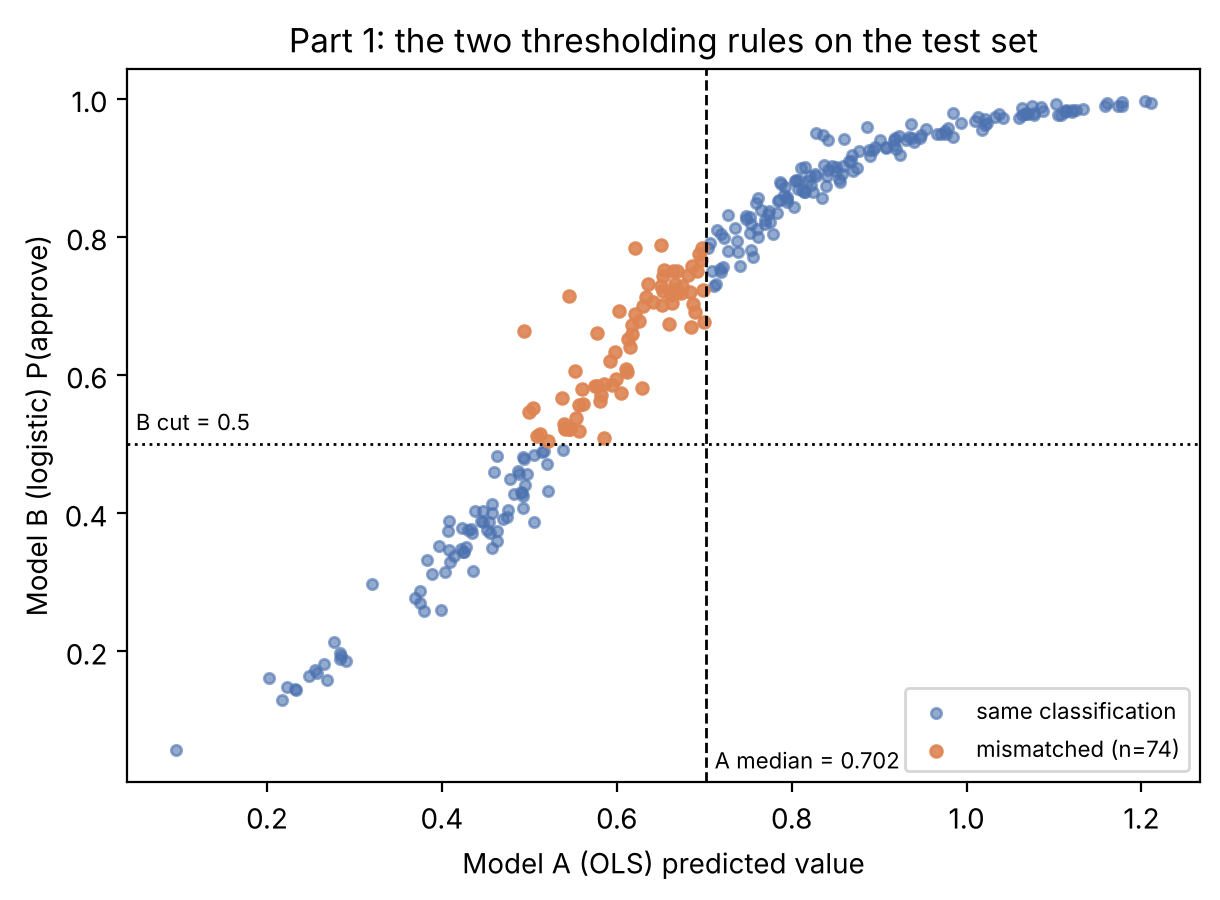

In [7]:
fig, ax = plt.subplots(figsize=(6.2, 4.6))
mm = (flagA != flagB).values
ax.scatter(pA[~mm], pB[~mm], s=14, c="#4C72B0", alpha=.6, label="same classification")
ax.scatter(pA[mm], pB[mm], s=18, c="#DD8452", alpha=.9, label=f"mismatched (n={mismatch})")
ax.axvline(medA, ls="--", c="k", lw=1); ax.axhline(0.5, ls=":", c="k", lw=1)
ax.text(medA + .01, .03, f"A median = {medA:.3f}", fontsize=8)
ax.text(.05, .52, "B cut = 0.5", fontsize=8)
ax.set_xlabel("Model A (OLS) predicted value"); ax.set_ylabel("Model B (logistic) P(approve)")
ax.set_title("Part 1: the two thresholding rules on the test set"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig("figures/p1_thresholds.png", dpi=170); plt.show()

## Part 2.1 — Simpson's paradox hunt: effect of **age**, split by **sex**
Logistic regressions on the full dataset (n = 1000): (1) everyone, (2) subgroup A = women, (3) subgroup B = men.
All three use the same specification: all predictors except the `personal_status_sex` dummies (sex is constant within a
subgroup). Age is standardised, so β is the change in log-odds of approval per 1 SD of age
(SD ≈ 11.4 years). The search that led here scanned three splits (sex, age ≤ 25, foreign worker) and every coefficient;
because that is a multiple-comparison search, the finding is then checked with (i) two simpler specifications and
(ii) a formal age × female interaction test.

In [8]:
SEX = [c for c in X_all if c.startswith("personal_status_sex")]
XS = X_all.drop(columns=SEX)
F, M = df.female == 1, df.female == 0
R["n_female"], R["n_male"] = int(F.sum()), int(M.sum())
R["approve_female"], R["approve_male"] = r3(y[F].mean()), r3(y[M].mean())

def fit(rows, cols):
    Xs = XS.loc[rows, cols]; Xs = Xs.loc[:, (Xs.std() > 0) | (Xs.columns == "const")]
    return sm.Logit(y[rows], Xs).fit(disp=0, maxiter=500)

def row(m, v):
    lo, hi = m.conf_int().loc[v]
    return dict(beta=r3(m.params[v]), se=r3(m.bse[v]), lo=r3(lo), hi=r3(hi), p=r3(m.pvalues[v]),
                OR=r3(np.exp(m.params[v])), n=int(m.nobs))

specs = {
  "full specification (all predictors)": list(XS.columns),
  "core specification (age, duration, amount, instalment rate, checking, history, savings)":
      ["const","age","duration","log_amount","installment_rate"] + [c for c in XS if c.startswith(("checking","credit_history","savings"))],
  "bivariate (age only)": ["const","age"],
}
simp = {}
for name, cols in specs.items():
    simp[name] = {g: row(fit(rows, cols), "age") for g, rows in
                  [("Full dataset", df.index), ("Subgroup A: women", df.index[F]), ("Subgroup B: men", df.index[M])]}
    # interaction test on pooled data: age x female
    Xi = XS[cols].copy(); Xi["female"] = df.female; Xi["age_x_female"] = Xi.age * df.female
    mi = sm.Logit(y, Xi).fit(disp=0, maxiter=500)
    simp[name]["interaction"] = row(mi, "age_x_female")
R["simpson"] = simp
for name, d in simp.items():
    print("\n==", name)
    print(pd.DataFrame(d).T[["beta","lo","hi","p","OR","n"]].to_string())

# a second key predictor reported for completeness (full specification)
mfull, mF, mM = (fit(r, list(XS.columns)) for r in (df.index, df.index[F], df.index[M]))
other = {}
for v in ["duration", "log_amount", "installment_rate", "checking=no_account", "savings=unknown_none"]:
    other[v] = {"Full": row(mfull, v), "Women": row(mF, v), "Men": row(mM, v)}
R["simpson_other"] = other
print("\nOther predictors (full specification):")
for v, d in other.items():
    print(f"{v:24s}", "  ".join(f"{g}: {x['beta']:+.3f} (p={x['p']:.3f})" for g, x in d.items()))


== full specification (all predictors)
                       beta        lo        hi         p        OR       n
Full dataset       0.162649 -0.039145  0.364442  0.114161  1.176623  1000.0
Subgroup A: women  0.787849  0.312872  1.262827  0.001150  2.198663   310.0
Subgroup B: men   -0.045501 -0.302451  0.211449  0.728536  0.955519   690.0
interaction        0.355840 -0.020119  0.731799  0.063585  1.427379  1000.0

== core specification (age, duration, amount, instalment rate, checking, history, savings)
                       beta        lo        hi         p        OR       n
Full dataset       0.146304 -0.016716  0.309325  0.078579  1.157549  1000.0
Subgroup A: women  0.465156  0.152407  0.777905  0.003556  1.592262   310.0
Subgroup B: men   -0.043879 -0.246411  0.158653  0.671103  0.957069   690.0
interaction        0.491549  0.136204  0.846894  0.006704  1.634847  1000.0

== bivariate (age only)
                       beta        lo        hi         p        OR       n
Full da

       mean_men  mean_women  size_men  size_women
band                                             
19-25     0.612       0.552        85         105
26-35     0.740       0.615       281         117
36-50     0.752       0.811       246          53
51-75     0.692       0.800        78          35


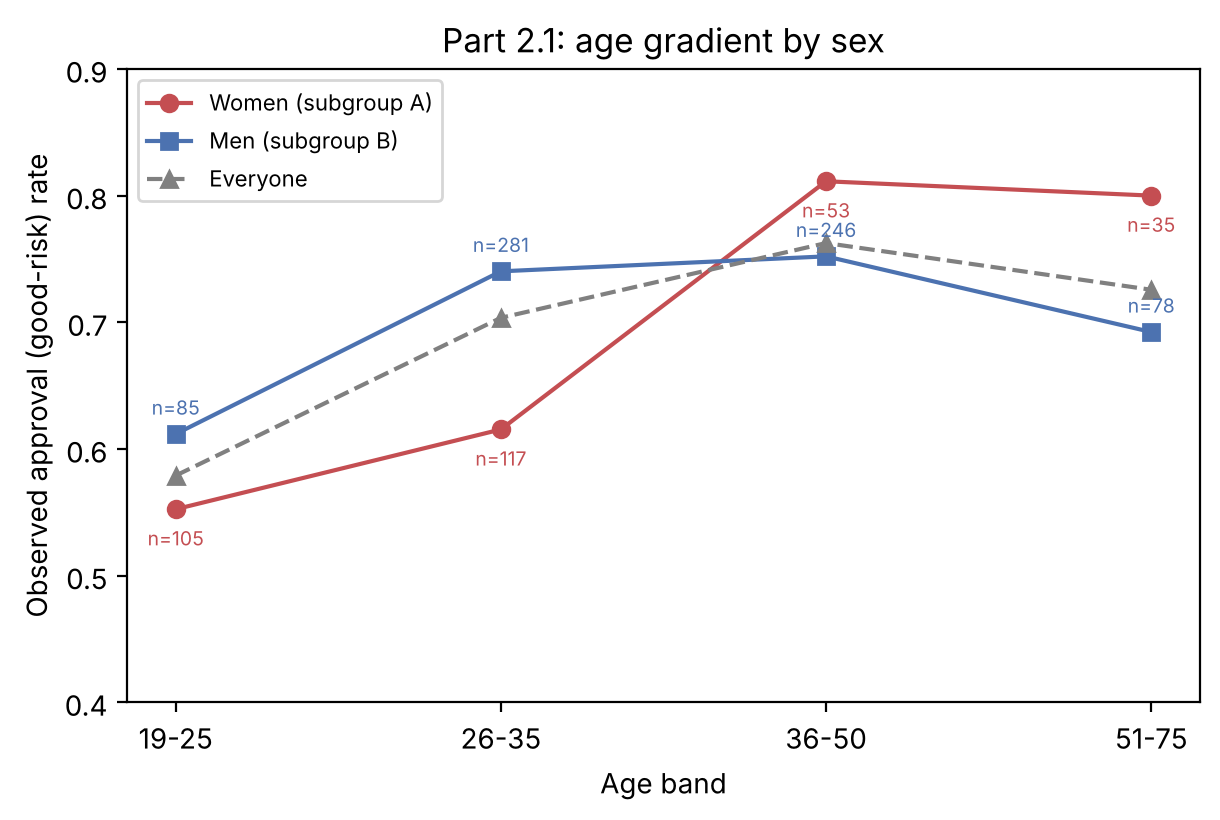

In [9]:
# what the age effect means in approval rates (raw data)
bands = pd.cut(df.age, [18, 25, 35, 50, 76], labels=["19-25", "26-35", "36-50", "51-75"])
tab = df.assign(band=bands).pivot_table(index="band", columns="female", values="approve", aggfunc=["mean","size"], observed=True)
tab.columns = [f"{a}_{'women' if b else 'men'}" for a, b in tab.columns]
R["simpson_bands"] = {str(k): {kk: r3(vv) for kk, vv in v.items()} for k, v in tab.to_dict(orient="index").items()}
print(tab.round(3))

fig, ax = plt.subplots(figsize=(6.2, 4.2))
x = np.arange(len(tab))
ax.plot(x, tab["mean_women"], "o-", c="#C44E52", label="Women (subgroup A)")
ax.plot(x, tab["mean_men"], "s-", c="#4C72B0", label="Men (subgroup B)")
ax.plot(x, df.assign(band=bands).groupby("band", observed=True).approve.mean(), "^--", c="grey", label="Everyone")
for i in range(len(tab)):
    ax.annotate(f"n={int(tab['size_women'].iloc[i])}", (x[i], tab["mean_women"].iloc[i]), textcoords="offset points", xytext=(0, -13), fontsize=7, ha="center", color="#C44E52")
    ax.annotate(f"n={int(tab['size_men'].iloc[i])}", (x[i], tab["mean_men"].iloc[i]), textcoords="offset points", xytext=(0, 7), fontsize=7, ha="center", color="#4C72B0")
ax.set_xticks(x); ax.set_xticklabels(tab.index); ax.set_xlabel("Age band"); ax.set_ylabel("Observed approval (good-risk) rate")
ax.set_title("Part 2.1: age gradient by sex"); ax.legend(fontsize=8); ax.set_ylim(.4, .9)
plt.tight_layout(); plt.savefig("figures/p21_age_by_sex.png", dpi=170); plt.show()

## Part 2.2 — Omitted-variable bias: dropping **loan duration**
Duration is a textbook confounder here: it drives the size of the loan (longer loans are bigger, r = 0.64 with log amount)
and it independently drives default risk (more months in which something can go wrong). Two logistic models on all
1000 rows: (1) full model, (2) the same model without `duration`.

In [10]:
full_m = sm.Logit(y, X_all).fit(disp=0)
red_m = sm.Logit(y, X_all.drop(columns=["duration"])).fit(disp=0)
PRED = ["log_amount", "installment_rate", "age", "existing_credits", "checking=no_account",
        "credit_history=critical_account", "savings=unknown_none", "purpose=car_used"]
ovb = pd.DataFrame({
    "beta_full": full_m.params[PRED], "p_full": full_m.pvalues[PRED],
    "beta_reduced": red_m.params[PRED], "p_reduced": red_m.pvalues[PRED]})
ovb["change"] = ovb.beta_reduced - ovb.beta_full
ovb["pct_chg"] = 100 * ovb.change / ovb.beta_full.abs()
ovb["pct_change_magnitude"] = 100 * (ovb.beta_reduced.abs() - ovb.beta_full.abs()) / ovb.beta_full.abs()
print(ovb.round(3).to_string())

# check against the omitted-variable-bias formula: bias ~ beta_duration * delta, delta from regressing duration on the others
aux = sm.OLS(X_all["duration"], X_all.drop(columns=["duration"])).fit()
pred_shift = full_m.params["duration"] * aux.params["log_amount"]
R["ovb"] = dict(
    table={k: {kk: r3(vv) for kk, vv in v.items()} for k, v in ovb.to_dict(orient="index").items()},
    beta_duration=r3(full_m.params["duration"]), p_duration=r3(full_m.pvalues["duration"]),
    corr_duration_logamount=r3(df[["duration","log_amount"]].corr().iloc[0, 1]),
    aux_delta_logamount=r3(aux.params["log_amount"]), predicted_shift_logamount=r3(pred_shift),
    actual_shift_logamount=r3(ovb.loc["log_amount","change"]),
    most_shifted=ovb.pct_chg.abs().idxmax(),
    aic_full=r3(full_m.aic), aic_red=r3(red_m.aic), llr_p=r3(1 - chi2.cdf(2*(full_m.llf - red_m.llf), 1)))
print("\nbeta(duration) in full model:", R["ovb"]["beta_duration"], "p =", R["ovb"]["p_duration"])
print("OVB formula: beta_dur x delta =", round(full_m.params['duration'], 3), "x", round(aux.params['log_amount'], 3),
      "=", round(pred_shift, 3), "| actual shift in log_amount:", round(ovb.loc['log_amount','change'], 3))
print("Most-shifted coefficient:", R["ovb"]["most_shifted"], "| AIC full/reduced:", R["ovb"]["aic_full"], R["ovb"]["aic_red"],
      "| LR test p:", R["ovb"]["llr_p"])

                                 beta_full  p_full  beta_reduced  p_reduced  change  pct_chg  pct_change_magnitude
log_amount                          -0.175   0.205        -0.488      0.000  -0.313 -178.961               178.961
installment_rate                    -0.309   0.002        -0.416      0.000  -0.107  -34.709                34.709
age                                  0.165   0.114         0.189      0.066   0.024   14.800                14.800
existing_credits                    -0.160   0.142        -0.134      0.215   0.026   16.514               -16.514
checking=no_account                  1.689   0.000         1.719      0.000   0.029    1.739                 1.739
credit_history=critical_account      1.496   0.001         1.553      0.000   0.057    3.825                 3.825
savings=unknown_none                 0.924   0.000         0.897      0.001  -0.027   -2.961                -2.961
purpose=car_used                     1.589   0.000         1.588      0.000  -0.

## Part 2.3 — Adversarial subset: confident but wrong
On the test set, using Model B: false positives with P(approve) ≥ 0.75 but actually bad, and false negatives with
P ≤ 0.25 but actually good. The brief asks for ~50 rows; if fewer exist all are used.

In [11]:
T = df.loc[test_idx].copy(); T["p"] = pB.values; T["y"] = yte.values
fp_hc = (T.p >= .75) & (T.y == 0); fn_hc = (T.p <= .25) & (T.y == 1)
adv_mask = fp_hc | fn_hc
n_adv = int(adv_mask.sum())
ADV = T[adv_mask] if n_adv <= 50 else T[adv_mask].sample(50, random_state=SEED)
print(f"High-confidence wrong: {n_adv} of {len(T)} = {100*n_adv/len(T):.2f}%  (FP>=0.75: {fp_hc.sum()}, FN<=0.25: {fn_hc.sum()})")
print("Rows used:", len(ADV), "(fewer than 50 exist, so all are used)" if n_adv <= 50 else "(random sample of 50)")

# calibration in the confident buckets: is the model over-confident or just facing irreducible noise?
hi, lo = T.p >= .75, T.p <= .25
R["p23"] = dict(n=n_adv, pct=r3(100*n_adv/len(T)), n_fp=int(fp_hc.sum()), n_fn=int(fn_hc.sum()), n_used=len(ADV),
                n_hi=int(hi.sum()), hi_mean_p=r3(T.p[hi].mean()), hi_bad_rate=r3(1 - T.y[hi].mean()),
                n_lo=int(lo.sum()), lo_mean_p=r3(T.p[lo].mean()), lo_good_rate=r3(T.y[lo].mean()))
print(f"Bucket P>=0.75: n={hi.sum()}, mean predicted P={T.p[hi].mean():.3f}, observed approval rate={T.y[hi].mean():.3f}")
print(f"Bucket P<=0.25: n={lo.sum()}, mean predicted P={T.p[lo].mean():.3f}, observed approval rate={T.y[lo].mean():.3f}")

High-confidence wrong: 19 of 300 = 6.33%  (FP>=0.75: 17, FN<=0.25: 2)
Rows used: 19 (fewer than 50 exist, so all are used)
Bucket P>=0.75: n=155, mean predicted P=0.897, observed approval rate=0.890
Bucket P<=0.25: n=16, mean predicted P=0.163, observed approval rate=0.125


In [12]:
def demo(D):
    return {"n": len(D), "age_mean": r3(D.age.mean()), "age_median": r3(D.age.median()),
            "pct_age_le25": r3(100*(D.age <= 25).mean()), "pct_age_26_40": r3(100*D.age.between(26, 40).mean()),
            "pct_age_gt40": r3(100*(D.age > 40).mean()), "pct_female": r3(100*D.female.mean()),
            "pct_foreign": r3(100*(D.foreign_worker == "A201").mean()),
            "duration_median": r3(D.duration.median()), "amount_median": r3(D.credit_amount.median()),
            "pct_actual_good": r3(100*D.approve.mean())}
dem = pd.DataFrame({"Adversarial subset": demo(ADV), "Full test set": demo(T)})
R["p23"]["demographics"] = dem.to_dict()
print(dem.to_string())

# Which strong 'approve' signals does the model rely on?  dummies with logistic beta >= 1.0
coefB = modelB.params.drop("const")
STRONG = coefB[(coefB >= 1.0) & coefB.index.str.contains("=")].sort_values(ascending=False)
print("\nDummies with beta >= 1.0 in Model B:\n", STRONG.round(3).to_string())

# The three account/history variables that carry the largest positive weights
KEY = ["checking=>=200DM", "checking=no_account", "credit_history=past_delay", "credit_history=critical_account",
       "savings=>=1000DM", "savings=unknown_none"]
XT = Xte.copy()
T["has_key"] = (XT[KEY].sum(axis=1) >= 1).values
T["n_strong"] = XT[STRONG.index].sum(axis=1).values
for nm, D in [("FP (conf. approve, actually bad)", T[fp_hc]), ("FN (conf. reject, actually good)", T[fn_hc]),
              ("Adversarial subset", ADV.assign(has_key=T.loc[ADV.index, "has_key"])), ("Full test set", T)]:
    print(f"{nm:34s} has >=1 key 'good-account' signal: {100*D.has_key.mean():5.1f}%  (n={len(D)})")
R["p23"].update(
    pct_fp_has_key=r3(100*T[fp_hc].has_key.mean()), pct_fn_has_key=r3(100*T[fn_hc].has_key.mean()),
    pct_adv_has_key=r3(100*T.loc[ADV.index, "has_key"].mean()), pct_test_has_key=r3(100*T.has_key.mean()),
    bad_rate_test_has_key=r3(1 - T[T.has_key].y.mean()), bad_rate_test_no_key=r3(1 - T[~T.has_key].y.mean()),
    mean_p_has_key=r3(T[T.has_key].p.mean()),
    key_betas={k: r3(coefB[k]) for k in KEY},
    fp_checking=T[fp_hc].checking.map(LABELS["checking"]).value_counts().to_dict(),
    fp_history=T[fp_hc].credit_history.map(LABELS["credit_history"]).value_counts().to_dict(),
    fp_savings=T[fp_hc].savings.map(LABELS["savings"]).value_counts().to_dict(),
    fp_savings_low_pct=r3(100*(T[fp_hc].savings == "A61").mean()),
    fp_mean_n_strong=r3(T[fp_hc].n_strong.mean()), test_mean_n_strong=r3(T.n_strong.mean()),
    fn_rows=T[fn_hc][["checking","credit_history","savings","duration","credit_amount","age","p"]].assign(
        checking=lambda d: d.checking.map(LABELS["checking"]), credit_history=lambda d: d.credit_history.map(LABELS["credit_history"]),
        savings=lambda d: d.savings.map(LABELS["savings"])).round(3).to_dict(orient="records"))
show = ADV[["checking","credit_history","savings","purpose","duration","credit_amount","age","female","p","approve"]].copy()
for c in ["checking","credit_history","savings","purpose"]: show[c] = show[c].map(LABELS[c])
show.sort_values("p", ascending=False)

                 Adversarial subset  Full test set
n                         19.000000     300.000000
age_mean                  36.052632      35.256667
age_median                34.000000      32.500000
pct_age_le25              21.052632      19.000000
pct_age_26_40             52.631579      53.333333
pct_age_gt40              26.315789      27.666667
pct_female                36.842105      31.000000
pct_foreign              100.000000      97.666667
duration_median           18.000000      18.000000
amount_median           2580.000000    2239.500000
pct_actual_good           10.526316      70.333333

Dummies with beta >= 1.0 in Model B:
 savings=>=1000DM                   2.303
purpose=retraining                 1.916
credit_history=critical_account    1.770
checking=no_account                1.585
purpose=car_used                   1.492
purpose=business                   1.257
foreign_worker=no                  1.183
savings=unknown_none               1.119
credit_history=past_d

,checking,credit_history,savings,purpose,duration,credit_amount,age,female,p,approve
754,no_account,past_delay,>=1000DM,repairs,12,1555,55,0,0.987835,0
190,no_account,existing_paid,>=1000DM,business,24,4591,54,0,0.986941,0
757,>=200DM,critical_account,unknown_none,radio_tv,15,1271,39,0,0.971376,0
92,no_account,critical_account,unknown_none,radio_tv,12,797,33,1,0.949194,0
349,0-200DM,critical_account,>=1000DM,education,9,1136,32,0,0.947008,0
780,0-200DM,critical_account,<100DM,radio_tv,39,4933,25,0,0.923753,0
439,>=200DM,all_paid_this_bank,<100DM,business,12,609,26,1,0.901878,0
249,no_account,existing_paid,<100DM,radio_tv,18,433,22,1,0.878596,0
56,0-200DM,existing_paid,unknown_none,radio_tv,12,6468,52,0,0.876645,0
645,no_account,past_delay,unknown_none,business,36,7980,27,0,0.872421,0


In [13]:
# Statistical diagnosis: (1) is an interaction missing?  Test checking=no_account x credit_history=critical_account
# and (2) default rate among applicants with a key signal vs the model's average prediction for them.
Xint = Xtr.copy()
Xint["noacct_x_critical"] = Xint["checking=no_account"] * Xint["credit_history=critical_account"]
Xint["noacct_x_logamt"] = Xint["checking=no_account"] * Xint["log_amount"]
Xint["noacct_x_duration"] = Xint["checking=no_account"] * Xint["duration"]
mint = sm.Logit(ytr, Xint).fit(disp=0)
lr = 2 * (mint.llf - modelB.llf)
R["p23"]["interaction_test"] = dict(LR=r3(lr), df=3, p=r3(1 - chi2.cdf(lr, 3)),
    betas={k: r3(mint.params[k]) for k in ["noacct_x_critical","noacct_x_logamt","noacct_x_duration"]},
    pvals={k: r3(mint.pvalues[k]) for k in ["noacct_x_critical","noacct_x_logamt","noacct_x_duration"]})
print("Interaction terms added to Model B:", R["p23"]["interaction_test"])
# linear-predictor decomposition for the FP rows: biggest single positive push
contrib = (Xte.loc[T[fp_hc].index] * modelB.params)
top = contrib.drop(columns="const").idxmax(axis=1).value_counts()
R["p23"]["fp_top_push"] = top.to_dict()
print("Largest single positive contribution in each confident-FP row:\n", top.to_string())

Interaction terms added to Model B: {'LR': 8.808287, 'df': 3, 'p': 0.031951, 'betas': {'noacct_x_critical': 0.387731, 'noacct_x_logamt': -0.939094, 'noacct_x_duration': 0.70324}, 'pvals': {'noacct_x_critical': 0.498946, 'noacct_x_logamt': 0.004823, 'noacct_x_duration': 0.020704}}
Largest single positive contribution in each confident-FP row:
 credit_history=critical_account    5
checking=no_account                4
savings=>=1000DM                   3
savings=unknown_none               2
purpose=business                   2
personal_status_sex=male_single    1


## Part 2.4 — Fairness trade-off analysis (sensitive variable: **age**)
Group A = young applicants (age ≤ 25), Group B = older applicants (age > 25), test set.
Ŷ = 1 means *approve*. For every threshold t ∈ {0.05, 0.15, …, 0.95}:
* DP = P(Ŷ=1 | A) / P(Ŷ=1 | B)
* EO = min(TPR_A / TPR_B, FPR_A / FPR_B)
* PP = P(Y=1 | Ŷ=1, A) / P(Y=1 | Ŷ=1, B)

Also reported: accuracy, expected misclassification cost using the UCI cost matrix (approving a bad applicant costs 5,
rejecting a good one costs 1) and 1,000-sample bootstrap 95% intervals, because Group A has only 57 test applicants.

In [14]:
A = (T.young == 1).values; B = ~A
yt = T.y.values; pt = T.p.values
R["p24_groups"] = dict(nA=int(A.sum()), nB=int(B.sum()), baseA=r3(yt[A].mean()), baseB=r3(yt[B].mean()),
                       negA=int((yt[A] == 0).sum()), negB=int((yt[B] == 0).sum()))
print(R["p24_groups"])

def metrics(yy, pp, a, t):
    yh = (pp >= t).astype(int); b = ~a
    def g(m):
        sel = yh[m].mean()
        tpr = yh[m & (yy == 1)].mean() if (m & (yy == 1)).any() else np.nan
        fpr = yh[m & (yy == 0)].mean() if (m & (yy == 0)).any() else np.nan
        ppv = yy[m & (yh == 1)].mean() if (m & (yh == 1)).any() else np.nan
        return sel, tpr, fpr, ppv
    sa, ta, fa, pa_ = g(a); sb, tb, fb, pb_ = g(b)
    div = lambda u, v: u / v if v and np.isfinite(v) and v > 0 else np.nan
    tr_, fr_ = div(ta, tb), div(fa, fb)
    eo = np.nanmin([tr_, fr_]) if np.isfinite([tr_, fr_]).any() else np.nan
    cost = (5 * ((yh == 1) & (yy == 0)).sum() + 1 * ((yh == 0) & (yy == 1)).sum()) / len(yy)
    return dict(t=t, sel_A=sa, sel_B=sb, TPR_A=ta, TPR_B=tb, FPR_A=fa, FPR_B=fb, PPV_A=pa_, PPV_B=pb_,
                DP=div(sa, sb), TPR_ratio=tr_, FPR_ratio=fr_, EO=eo, PP=div(pa_, pb_),
                accuracy=(yh == yy).mean(), approval_rate=yh.mean(), cost_per_applicant=cost)

TH = np.round(np.arange(0.05, 0.96, 0.1), 2)
fair = pd.DataFrame([metrics(yt, pt, A, t) for t in TH]).set_index("t")

# bootstrap CIs
rng = np.random.default_rng(SEED); boots = {t: [] for t in TH}
for _ in range(1000):
    i = rng.integers(0, len(yt), len(yt))
    for t in TH:
        m = metrics(yt[i], pt[i], A[i], t); boots[t].append((m["DP"], m["EO"], m["PP"]))
for t in TH:
    bb = np.array(boots[t], dtype=float)
    for j, k in enumerate(["DP", "EO", "PP"]):
        fair.loc[t, k + "_lo"], fair.loc[t, k + "_hi"] = np.nanpercentile(bb[:, j], [2.5, 97.5])
R["fair"] = {str(t): {k: r3(v) for k, v in row.items()} for t, row in fair.iterrows()}
print(fair[["DP","EO","TPR_ratio","FPR_ratio","PP","accuracy","approval_rate","cost_per_applicant","sel_A","sel_B"]].round(3).to_string())
print("\nBootstrap 95% CI:\n", fair[["DP_lo","DP_hi","EO_lo","EO_hi","PP_lo","PP_hi"]].round(3).to_string())

{'nA': 57, 'nB': 243, 'baseA': 0.526316, 'baseB': 0.744856, 'negA': 27, 'negB': 62}


         DP     EO  TPR_ratio  FPR_ratio     PP  accuracy  approval_rate  cost_per_applicant  sel_A  sel_B
t                                                                                                         
0.05  1.000  1.000      1.000      1.000  0.707     0.703          1.000               1.483  1.000  1.000
0.15  0.977  0.957      1.006      0.957  0.727     0.713          0.983               1.420  0.965  0.988
0.25  0.933  0.893      1.011      0.893  0.766     0.743          0.947               1.257  0.895  0.959
0.35  0.864  0.750      1.011      0.750  0.827     0.753          0.890               1.113  0.789  0.914
0.45  0.870  0.829      1.018      0.829  0.827     0.757          0.787               0.897  0.702  0.807
0.55  0.843  0.946      0.946      1.052  0.793     0.770          0.707               0.697  0.614  0.728
0.65  0.885  1.027      1.027      1.148  0.820     0.757          0.640               0.603  0.579  0.654
0.75  0.820  0.707      1.083      0.

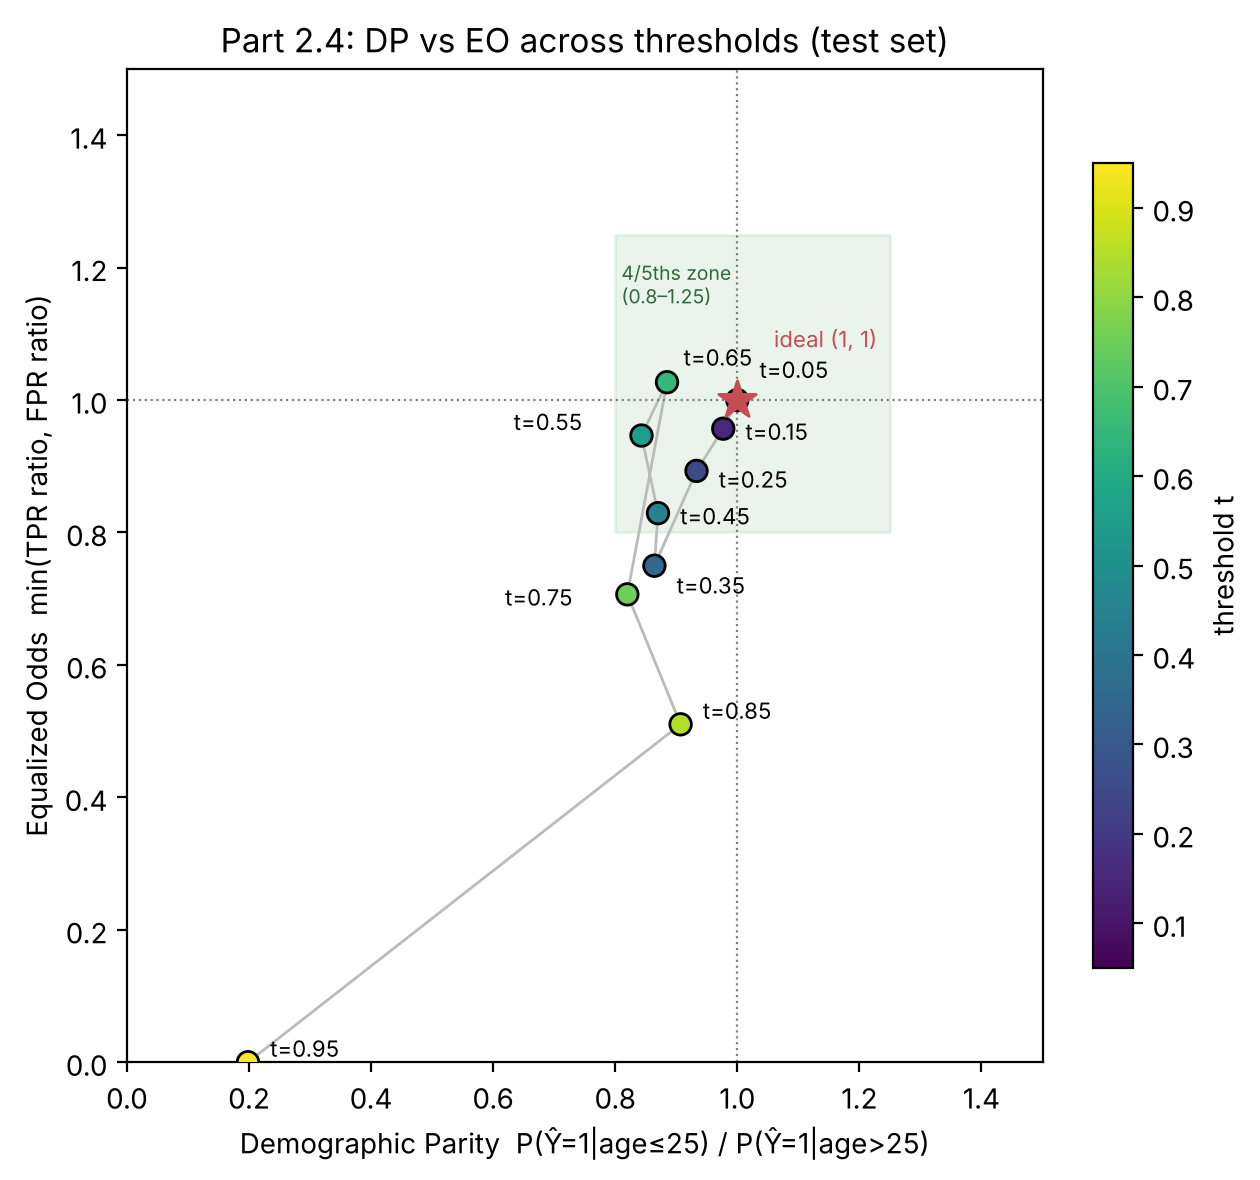

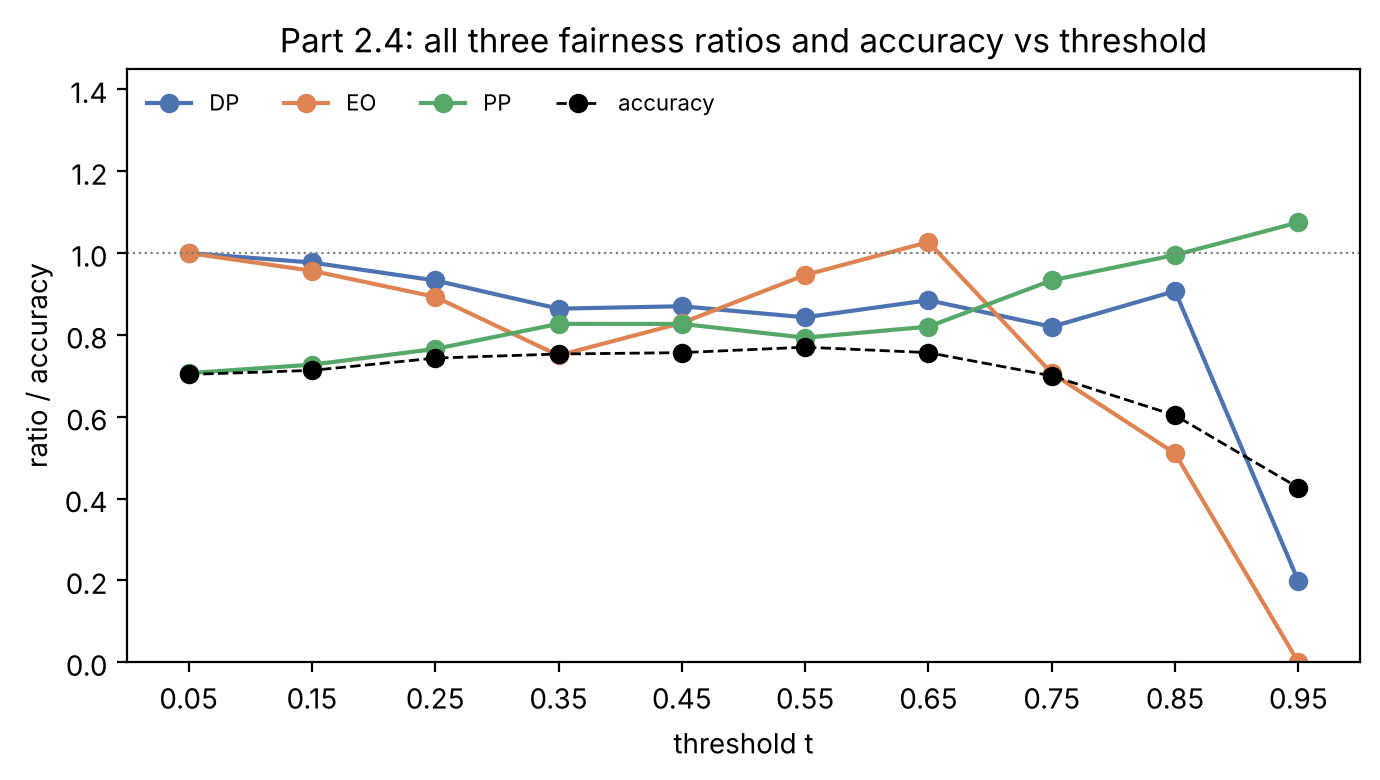

In [15]:
fig, ax = plt.subplots(figsize=(6.4, 6.0))
ax.add_patch(plt.Rectangle((0.8, 0.8), 0.45, 0.45, color="#55A868", alpha=.12))
ax.text(0.81, 1.21, "4/5ths zone\n(0.8–1.25)", fontsize=7, color="#2d6b3c", va="top")
ax.axvline(1, c="grey", lw=.8, ls=":"); ax.axhline(1, c="grey", lw=.8, ls=":")
ax.plot(fair.DP.clip(0, 1.5), fair.EO.clip(0, 1.5), "-", c="#bbbbbb", lw=1, zorder=1)
sc_ = ax.scatter(fair.DP.clip(0, 1.5), fair.EO.clip(0, 1.5), c=fair.index, cmap="viridis", s=60, zorder=3, edgecolor="k")
OFF = {0.05: (8, 8), 0.15: (8, -4), 0.25: (8, -6), 0.35: (8, -10), 0.45: (8, -4), 0.55: (-46, 2), 0.65: (6, 6),
       0.75: (-44, -4), 0.85: (8, 2), 0.95: (8, 2)}
for t, r in fair.iterrows():
    ax.annotate(f"t={t:.2f}", (min(r.DP, 1.5), min(r.EO, 1.5)), textcoords="offset points", xytext=OFF.get(round(t, 2), (6, 4)), fontsize=8)
ax.scatter([1], [1], marker="*", s=200, c="#C44E52", zorder=4); ax.annotate("ideal (1, 1)", (1, 1), xytext=(1.06, 1.08), fontsize=8, color="#C44E52")
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5)
ax.set_xlabel("Demographic Parity  P(Ŷ=1|age≤25) / P(Ŷ=1|age>25)")
ax.set_ylabel("Equalized Odds  min(TPR ratio, FPR ratio)")
ax.set_title("Part 2.4: DP vs EO across thresholds (test set)")
plt.colorbar(sc_, ax=ax, label="threshold t", fraction=.04)
plt.tight_layout(); plt.savefig("figures/p24_tradeoff.png", dpi=170); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.0))
for k, c in [("DP", "#4C72B0"), ("EO", "#DD8452"), ("PP", "#55A868"), ("accuracy", "k")]:
    ax.plot(fair.index, fair[k], "o-", c=c, label=k, lw=1.5 if k != "accuracy" else 1, ls="-" if k != "accuracy" else "--")
ax.axhline(1, c="grey", lw=.8, ls=":"); ax.set_xticks(TH); ax.set_xlabel("threshold t"); ax.set_ylabel("ratio / accuracy")
ax.set_title("Part 2.4: all three fairness ratios and accuracy vs threshold"); ax.set_ylim(0, 1.45); ax.set_xlim(0, 1.0)
ax.legend(fontsize=8, ncol=4, loc="upper left", frameon=False)
plt.tight_layout(); plt.savefig("figures/p24_metrics.png", dpi=170); plt.show()

In [16]:
# Quantify the trade-off: adjacent threshold moves where DP moves toward 1 while EO moves away from 1
moves = []
for t0, t1 in list(zip(TH[:-1], TH[1:])) + list(zip(TH[1:], TH[:-1])):
    a, b = fair.loc[t0], fair.loc[t1]
    if not np.isfinite([a.DP, b.DP, a.EO, b.EO]).all(): continue
    dpg = abs(1 - a.DP) - abs(1 - b.DP); eol = abs(1 - b.EO) - abs(1 - a.EO)
    if dpg > 0 and eol > 0:
        moves.append(dict(frm=t0, to=t1, DP_from=a.DP, DP_to=b.DP, DP_gain_pct=100*(b.DP - a.DP)/a.DP,
                          EO_from=a.EO, EO_to=b.EO, EO_loss_pct=100*(a.EO - b.EO)/a.EO,
                          acc_from=a.accuracy, acc_to=b.accuracy))
moves = pd.DataFrame(moves); moves["cost_W_over_Z"] = moves.EO_loss_pct / moves.DP_gain_pct
print(moves.round(3).to_string())
head = moves.sort_values("DP_gain_pct", ascending=False).iloc[0]
R["tradeoff_moves"] = [{k: r3(v) for k, v in m.items()} for m in moves.to_dict(orient="records")]
R["tradeoff_headline"] = {k: r3(v) for k, v in head.items()}
print(f"\nIf you improve DP from {head.DP_from:.3f} to {head.DP_to:.3f} (a {head.DP_gain_pct:.1f}% gain) by moving t from "
      f"{head.frm:.2f} to {head.to:.2f}, EO drops from {head.EO_from:.3f} to {head.EO_to:.3f} (a {head.EO_loss_pct:.1f}% loss). "
      f"The trade-off cost is {head.EO_loss_pct:.1f}/{head.DP_gain_pct:.1f} = {head.cost_W_over_Z:.2f}.")
best_acc = fair.accuracy.idxmax(); best_cost = fair.cost_per_applicant.idxmin()
R["best_acc_t"], R["best_cost_t"] = float(best_acc), float(best_cost)
print("Accuracy-maximising t:", best_acc, "| cost-minimising t (UCI 5:1 cost matrix):", best_cost,
      "| theoretical Bayes cut for 5:1 costs = 5/6 =", round(5/6, 3))
# thresholds meeting every metric within the four-fifths band
ok = fair[(fair[["DP","EO","PP"]] >= 0.8).all(axis=1) & (fair[["DP","EO","PP"]] <= 1.25).all(axis=1)]
R["all_three_in_band"] = [float(t) for t in ok.index]
print("Thresholds with DP, EO and PP all inside [0.8, 1.25]:", list(ok.index))

    frm    to  DP_from  DP_to  DP_gain_pct  EO_from  EO_to  EO_loss_pct  acc_from  acc_to  cost_W_over_Z
0  0.75  0.85    0.820  0.907       10.638    0.707  0.510       27.778      0.70   0.603          2.611
1  0.55  0.45    0.843  0.870        3.207    0.946  0.829       12.382      0.77   0.757          3.861

If you improve DP from 0.820 to 0.907 (a 10.6% gain) by moving t from 0.75 to 0.85, EO drops from 0.707 to 0.510 (a 27.8% loss). The trade-off cost is 27.8/10.6 = 2.61.
Accuracy-maximising t: 0.55 | cost-minimising t (UCI 5:1 cost matrix): 0.75 | theoretical Bayes cut for 5:1 costs = 5/6 = 0.833
Thresholds with DP, EO and PP all inside [0.8, 1.25]: [0.45, 0.65]


In [17]:
# Scenario for Part 3 Q6: one young and one older applicant with almost the same model score
T["score_gap"] = 0.0
ya = T[(T.young == 1)]; ob = T[(T.young == 0)]
pairs = []
for i, r in ya.iterrows():
    j = (ob.p - r.p).abs().idxmin(); pairs.append((i, j, abs(ob.p[j] - r.p)))
R["p24_example_band"] = {}
for t in [0.55, 0.65, 0.75, 0.85]:
    R["p24_example_band"][str(t)] = dict(young_approved=int(((ya.p >= t)).sum()), young_n=len(ya),
        young_good_rejected=int(((ya.p < t) & (ya.y == 1)).sum()), young_bad_approved=int(((ya.p >= t) & (ya.y == 0)).sum()),
        old_approved=int((ob.p >= t).sum()), old_n=len(ob),
        old_good_rejected=int(((ob.p < t) & (ob.y == 1)).sum()), old_bad_approved=int(((ob.p >= t) & (ob.y == 0)).sum()))
print(pd.DataFrame(R["p24_example_band"]).T)
# young applicants that are good risks with scores between 0.65 and 0.85 (approved at 0.65, rejected at 0.85)
mid = ya[(ya.p >= 0.65) & (ya.p < 0.85)]
R["p24_young_mid"] = dict(n=len(mid), good=int(mid.y.sum()))
midB = ob[(ob.p >= 0.65) & (ob.p < 0.85)]
R["p24_old_mid"] = dict(n=len(midB), good=int(midB.y.sum()))
print("young with 0.65<=p<0.85:", R["p24_young_mid"], "| older:", R["p24_old_mid"])

      young_approved  young_n  young_good_rejected  young_bad_approved  old_approved  old_n  old_good_rejected  old_bad_approved
0.55              35       57                    6                  11           177    243                 28                24
0.65              33       57                    6                   9           159    243                 40                18
0.75              25       57                    9                   4           130    243                 64                13
0.85              20       57                   12                   2            94    243                 96                 9
young with 0.65<=p<0.85: {'n': 13, 'good': 6} | older: {'n': 65, 'good': 56}


In [18]:
with open("results.json", "w") as f:
    json.dump(R, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("Saved results.json with", len(R), "top-level entries; figures in ./figures")

Saved results.json with 31 top-level entries; figures in ./figures
